# 02 - Transformasi dan agregasi PySpark
Spark local[2], skema eksplisit, desimal untuk uang. Transformasi: standardisasi tanggal/tipe, normalisasi dimensi, gross/net sales dan diskon, bulan dan basket band, karantina invalid/duplikat.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd() if (Path.cwd()/"sales_project.py").exists() else Path.cwd().parent
assert (ROOT/"sales_project.py").exists(), "Buka notebook dari folder proyek/notebooks"
sys.path.insert(0,str(ROOT))
os.chdir(ROOT)
java_candidates = list((ROOT/".runtime/java").glob("*/bin/java.exe"))
if java_candidates:
    os.environ["JAVA_HOME"] = str(java_candidates[0].parent.parent)
os.environ["PYSPARK_PYTHON"] = sys.executable
from sales_project import *
print("Project:", ROOT.name)


Project: big-data-sales-analytics


In [2]:
result = spark_stage()
display(result)

== Physical Plan ==
AdaptiveSparkPlan (28)
+- InMemoryTableScan (1)
      +- InMemoryRelation (2)
            +- AdaptiveSparkPlan (27)
               +- == Final Plan ==
                  * Project (9)
                  +- * Project (8)
                     +- * Project (7)
                        +- * Project (6)
                           +- * Project (5)
                              +- * Filter (4)
                                 +- Scan csv  (3)
               +- == Initial Plan ==
                  Project (26)
                  +- BroadcastHashJoin LeftAnti BuildRight (25)
                     :- Project (15)
                     :  +- Project (14)
                     :     +- Project (13)
                     :        +- Project (12)
                     :           +- Filter (11)
                     :              +- Scan csv  (10)
                     +- BroadcastExchange (24)
                        +- Project (23)
                           +- Filter (22)
              

{
  "source_rows": 100000,
  "accepted_rows": 100000,
  "invalid_rows": 0,
  "duplicate_rows": 0,
  "reference_monthly_match": true,
  "sql_profile_match": true,
  "parquet_exact_roundtrip": true,
  "spark_parquet_rows": 100000,
  "parquet_write_seconds": 0.6097201999946265,
  "spark_version": "3.5.3",
  "transformations": [
    "Cast dates and numeric types",
    "Normalize dimension whitespace",
    "Calculate gross/net sales and discount",
    "Derive month and basket band",
    "Quarantine invalid and duplicate records"
  ]
}
{'transactions': 100000, 'units_sold': 551507, 'gross_sales': 58074226000.0, 'net_sales': 54856691900.0, 'discount_amount': 3217534100.0, 'average_transaction': 548566.919, 'date_min': '2024-01-01', 'date_max': '2026-09-30'}


{'source_rows': 100000,
 'accepted_rows': 100000,
 'invalid_rows': 0,
 'duplicate_rows': 0,
 'reference_monthly_match': True,
 'sql_profile_match': True,
 'parquet_exact_roundtrip': True,
 'spark_parquet_rows': 100000,
 'parquet_write_seconds': 0.6097201999946265,
 'spark_version': '3.5.3',
 'transformations': ['Cast dates and numeric types',
  'Normalize dimension whitespace',
  'Calculate gross/net sales and discount',
  'Derive month and basket band',
  'Quarantine invalid and duplicate records']}

## Penyimpanan lab
Hasil transformasi Spark dikumpulkan ke driver, lalu ditulis sebagai Parquet Snappy dengan Arrow agar tidak memerlukan DLL Hadoop di Windows. Spark membaca ulang Parquet. Pendekatan ini sesuai data lab 100 ribu baris; untuk produksi besar gunakan penulisan Spark terdistribusi di Linux/cluster.

In [3]:
import pandas as pd
for dimension in ["month","branch","category","payment_method"]:
    print(dimension)
    display(pd.read_csv(OUT/f"aggregates/by_{dimension}.csv"))

month


,month,transactions,units_sold,net_sales
0,2024-01,3163,17365,1.744161e+09
1,2024-02,2906,15879,1.550383e+09
2,2024-03,3206,17874,1.775595e+09
3,2024-04,2928,16016,1.597627e+09
4,2024-05,3123,17162,1.733182e+09
5,2024-06,2941,15833,1.573383e+09
6,2024-07,3056,16944,1.699022e+09
7,2024-08,3082,17115,1.686428e+09
8,2024-09,3044,16847,1.695288e+09
9,2024-10,3158,17742,1.783478e+09


branch


,branch,transactions,units_sold,net_sales
0,Bandung,12404,67917,6.802998e+09
1,Denpasar,12600,69316,6.789201e+09
2,Jakarta,12480,69049,6.886854e+09
3,Makassar,12643,69849,6.996060e+09
4,Medan,12411,68488,6.792641e+09
5,Semarang,12403,68557,6.878749e+09
6,Surabaya,12659,69863,6.965935e+09
7,Yogyakarta,12400,68468,6.744254e+09


category


,category,transactions,units_sold,net_sales
0,Elektronik,15897,87601,1.754525e+10
1,Fashion,18036,99330,1.310403e+10
2,Kebutuhan Rumah,20122,110567,7.976164e+09
3,Kesehatan,15916,88062,5.380579e+09
4,Makanan,18123,99913,3.873517e+09
5,Olahraga,11906,66034,6.977153e+09


payment_method


,payment_method,transactions,units_sold,net_sales
0,E-Wallet,31833,175265,1.741391e+10
1,Kartu,17955,99133,9.819740e+09
2,Transfer,35267,195320,1.943990e+10
3,Tunai,14945,81789,8.183150e+09


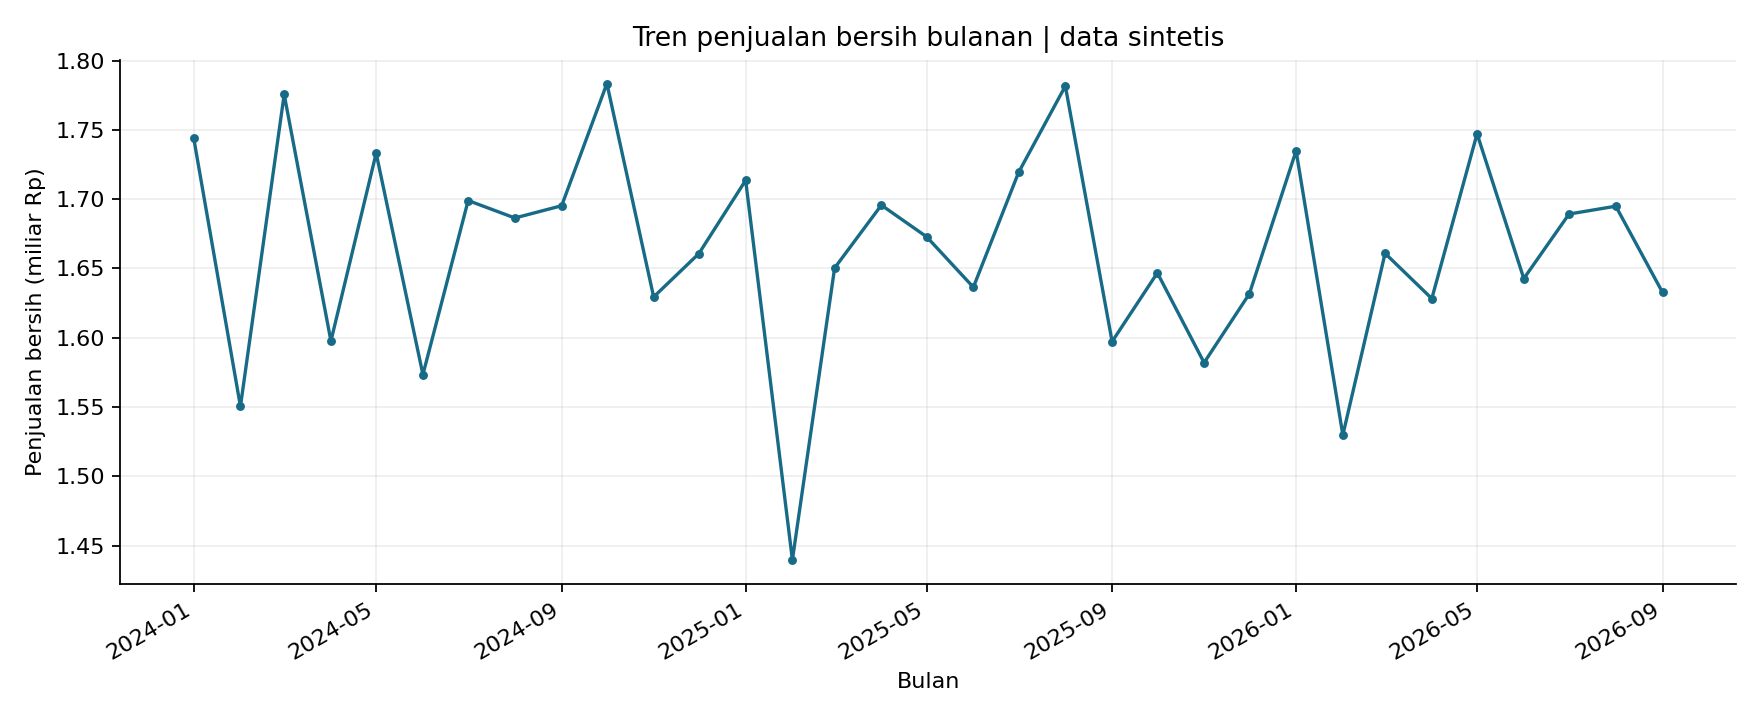

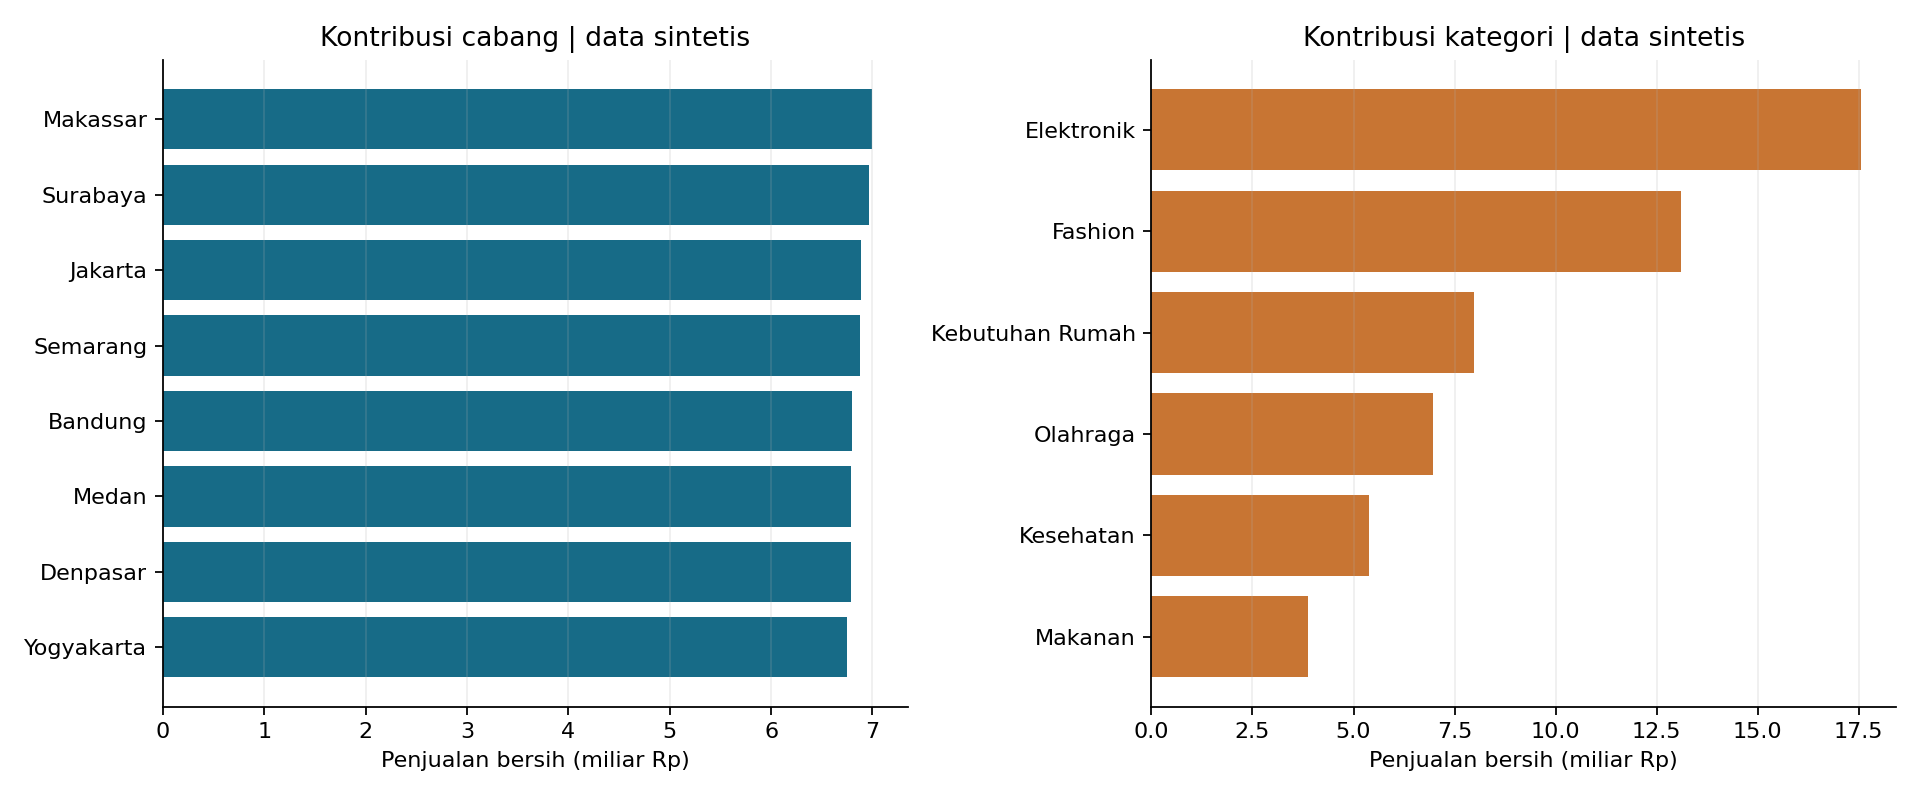

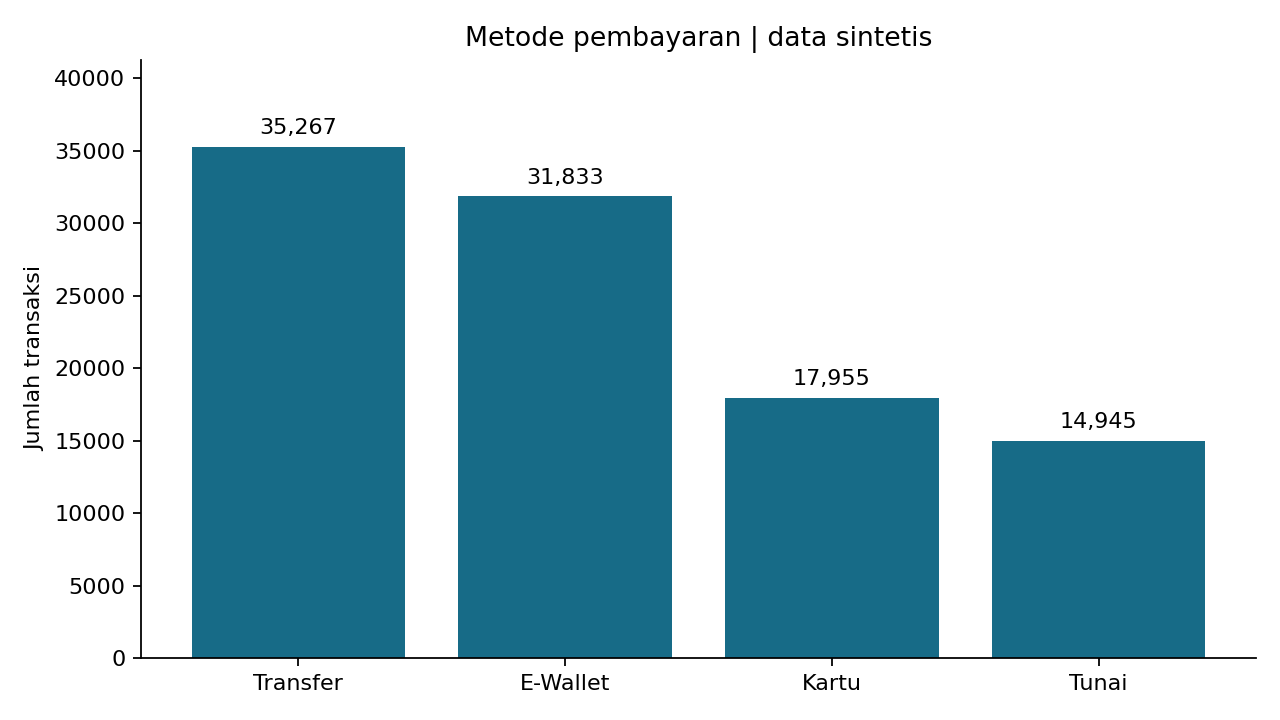

In [4]:
from IPython.display import Image, display
for chart in sorted((OUT/"charts").glob("*.png")):
    display(Image(filename=str(chart)))